# **SentaAI: FIAP Global Solution 2026**
### **Data Science & Statistical Computing**

> **Escopo Técnico:** wrangling, análise exploratória, regressão linear e regressão logística sobre a base pública de atrasos de ônibus de Toronto (TTC Bus Delay, 2022).
> **Grupo:** SentaAI · Tema: *CITIZEN TECH*

---

## **1. Solução original** *(desenvolvida nas entregas das outras disciplinas)*

Protótipo de interface instalada na parte de fora dos ônibus que registra entradas e saídas de passageiros pela **catraca** e por **sensores nas portas**.

**O que o sistema infere**

- Volume de pessoas no transporte
- Lugares disponíveis
- Entradas irregulares pela porta dos fundos

**GitHub:** [github.com/SentaAI](https://github.com/SentaAI)

---

## **2. Nessa entrega** *(Data Science & Statistical Computing)*

Nesta entrega, trabalhamos com a base pública de atrasos de ônibus da TTC (*Toronto Transit Commission*), disponibilizada pelo portal [Open Data Toronto](https://open.toronto.ca/dataset/ttc-bus-delay-data/). Escolhemos esses dados porque a superlotação, o problema que o SentaAI quer resolver, começa no atraso: quando um ônibus atrasa, os passageiros se acumulam no ponto, o veículo seguinte chega mais cheio e os dois passam a circular colados um no outro. É o chamado **efeito comboio** (*bus bunching*). Quanto maior a lacuna entre dois veículos (`Min Gap` na base original, `Intervalo_Min` neste notebook), pior fica esse efeito.

Por isso, prever o atraso é um passo direto para prever a lotação que o painel externo do SentaAI mostra antes do embarque. Construímos dois modelos, cada um respondendo a uma pergunta de negócio:

| Modelo | Pergunta de negócio | Alvo |
|:---|:---|:---|
| Regressão Linear | Quantos minutos o ônibus vai atrasar? | `Atraso_Min` (minutos) |
| Regressão Logística | Qual a probabilidade de o atraso ser crítico (risco de superlotação)? | `Atraso_Critico` (0/1) |

### **Integrantes**

- Arthur Berlofa Bosi (RM 564438)
- Levi de Jesus (RM 563279)
- Luigi Borghi (RM 563096)
- Ulisses Ribeiro (RM 562230)

---

## **3. Configuração do ambiente**

### **3.1 Imports básicos e carga dos dados**

In [1]:
# bibliotecas do sistema para listar arquivos e silenciar avisos
import os
import warnings

# bibliotecas de manipulação numérica, de tabelas e de gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# os avisos de versão poluem a saída, então ficam desligados
warnings.filterwarnings('ignore')

# lista os arquivos disponíveis no ambiente do Kaggle
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [2]:
df = pd.read_csv('../input/toronto-bus-delay-2022/ttc-bus-delay-data-2022.csv') #importing the dataset

### **3.2 Estrutura dos dados brutos (como vieram na importação)**

Antes de qualquer tratamento, registramos exatamente o que chegou do arquivo, no caso o número de linhas e colunas, o nome e o tipo de cada coluna, a quantidade de nulos e um exemplo de valor. Os nomes ainda estão em inglês, porque a tradução só acontece na Seção 4.2.

Dicionário das colunas originais da base da TTC:

| Coluna | O que representa |
|:---|:---|
| `Date` | Data da ocorrência |
| `Route` | Número da linha de ônibus |
| `Time` | Horário do registro, no formato `HH:MM` |
| `Day` | Dia da semana |
| `Location` | Local da ocorrência (cruzamento ou parada) |
| `Incident` | Tipo da ocorrência que causou o atraso |
| `Min Delay` | Atraso do ônibus, em minutos |
| `Min Gap` | Intervalo, em minutos, entre o ônibus afetado e o veículo seguinte |
| `Direction` | Sentido da viagem (N, S, E, W ou ambos) |
| `Vehicle` | Número de identificação do veículo |

In [3]:
# função que resume cada coluna com o tipo, a quantidade de nulos, os valores únicos e um exemplo
def descrever_colunas(tabela: pd.DataFrame) -> pd.DataFrame:
    """Monta um quadro com nome, tipo, nulos, valores únicos e exemplo de cada coluna."""
    return pd.DataFrame({
        "Tipo (pandas)": tabela.dtypes.astype(str),
        "Nulos": tabela.isna().sum(),
        "% de nulos": (tabela.isna().mean() * 100).round(1),
        "Valores únicos": tabela.nunique(),
        "Exemplo (1ª linha)": tabela.iloc[0],
    }).rename_axis("Coluna")


# dimensões do arquivo exatamente como foi lido, sem nenhuma modificação
print(f"Dados brutos: {df.shape[0]:,} linhas x {df.shape[1]} colunas")

# quadro com o nome e o tipo de cada coluna importada
display(descrever_colunas(df))

# primeiras linhas do arquivo original para conferir os valores
display(df.head(3))

Dados brutos: 58,707 linhas x 10 colunas


,Tipo (pandas),Nulos,% de nulos,Valores únicos,Exemplo (1ª linha)
Coluna,,,,,
Date,object,0,0.0,365,2022-01-01
Route,object,384,0.7,249,320
Time,object,0,0.0,1440,02:00
Day,object,0,0.0,7,Saturday
Location,object,0,0.0,10028,YONGE AND DUNDAS
Incident,object,0,0.0,15,General Delay
Min Delay,int64,0,0.0,505,0
Min Gap,int64,0,0.0,555,0
Direction,object,10480,17.9,19,NaN


,Date,Route,Time,Day,Location,Incident,Min Delay,Min Gap,Direction,Vehicle
0,2022-01-01,320,02:00,Saturday,YONGE AND DUNDAS,General Delay,0,0,NaN,8531
1,2022-01-01,325,02:00,Saturday,OVERLEA AND THORCLIFFE,Diversion,131,161,W,8658
2,2022-01-01,320,02:00,Saturday,YONGE AND STEELES,Operations - Operator,17,20,S,0


**O que observamos nos dados brutos**

- **Tamanho e tipos.** O arquivo traz 58.707 linhas e 10 colunas. Sete delas chegam como texto (`object`): `Date`, `Route`, `Time`, `Day`, `Location`, `Incident` e `Direction`. Só `Min Delay`, `Min Gap` e `Vehicle` chegam como número inteiro (`int64`).
- **Data e hora como texto.** `Date` e `Time` não foram reconhecidas como data e hora. Por isso, a hora só pode ser usada depois de extraída do texto `HH:MM`, o que fazemos na Seção 5.1.
- **Rota é um código, não uma quantidade.** A `Route` tem 249 valores distintos (como 320 e 325) e precisa ser tratada como categoria, e não como número.
- **Nulos concentrados em duas colunas.** A `Direction` tem 10.480 nulos (17,9%) e a `Route` tem 384 (0,7%). As demais colunas vêm completas.
- **Direção com valores inválidos.** A `Direction` tem 19 valores distintos, mas só cinco são válidos (N, S, E, W e B). O restante são códigos soltos, que tratamos como `Desconhecida`.
- **Colunas que descartamos.** A `Location` tem 10.028 valores distintos, e a `Vehicle` tem 2.305 identificadores. Com tanta variedade, nenhuma das duas generaliza para ônibus ou locais novos, e por isso ficam fora do modelo.

### **3.3 Imports de modelagem e parâmetros globais**

Aqui reunimos os imports de modelagem e os parâmetros globais, para que qualquer pessoa consiga reproduzir os resultados:

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    ConfusionMatrixDisplay, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, roc_auc_score,
)

RANDOM_STATE = 42        # semente única para que o split e os modelos sejam reprodutíveis
LIMIAR_CRITICO = 15      # em minutos, acima desse valor o atraso é considerado crítico
LIMITE_OUTLIER = 240     # em minutos, acima desse valor o registro é tratado como evento extraordinário

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

## **4. Contexto e Variáveis-Alvo** *(Etapa 1)*

### **4.1 Perguntas de negócio e variáveis-alvo**

O SentaAI precisa saber, antes de o ônibus chegar ao ponto, se ele tende a vir lotado. Para isso, transformamos as duas perguntas de negócio apresentadas na introdução em tarefas de aprendizado supervisionado:

- **Regressão Linear:** o alvo é o próprio `Atraso_Min`, o atraso em minutos.
- **Regressão Logística:** criamos a variável binária `Atraso_Critico`, que vale 1 quando o atraso passa de 15 minutos e 0 caso contrário. O corte de 15 minutos é uma definição nossa: a partir dele, assumimos que o acúmulo de passageiros já compromete o ônibus seguinte.

### **4.2 Fonte dos dados**

*TTC Bus Delay Data*, Open Data Toronto (licença *Open Government Licence – Toronto*), ano de 2022. Cada linha é uma ocorrência de atraso registrada pela operadora de transporte.

In [5]:
# Padronização dos nomes das colunas para português (a base original está em inglês)
COLUNAS_PT = {
    "Date": "Data", "Route": "Rota", "Time": "Horario", "Day": "Dia_Semana", "Location": "Local",
    "Incident": "Incidente", "Min Delay": "Atraso_Min", "Min Gap": "Intervalo_Min",
    "Direction": "Direcao", "Vehicle": "Veiculo",
}
df = df.rename(columns=COLUNAS_PT)

# Tradução dos registros (valores das colunas categóricas); valores sem correspondência são mantidos
DIAS_PT = {"Monday": "Segunda", "Tuesday": "Terça", "Wednesday": "Quarta", "Thursday": "Quinta",
           "Friday": "Sexta", "Saturday": "Sábado", "Sunday": "Domingo"}
DIRECOES_PT = {"N": "N", "S": "S", "E": "L", "W": "O", "B": "Ambas"}   # L = leste, O = oeste
INCIDENTES_PT = {
    "Operations - Operator": "Operação - Operador", "Mechanical": "Mecânico",
    "Collision - TTC": "Colisão - TTC", "Security": "Segurança", "Utilized Off Route": "Uso fora de rota",
    "General Delay": "Atraso geral", "Diversion": "Desvio", "Emergency Services": "Serviços de emergência",
    "Cleaning - Unsanitary": "Limpeza - Insalubre", "Investigation": "Investigação", "Vision": "Visibilidade",
    "Road Blocked - NON-TTC Collision": "Via bloqueada - colisão não TTC", "Held By": "Retido por",
    "Late Entering Service": "Entrada tardia em serviço", "Cleaning - Disinfection": "Limpeza - Desinfecção",
}

df["Dia_Semana"] = df["Dia_Semana"].map(DIAS_PT).fillna(df["Dia_Semana"])
df["Incidente"] = df["Incidente"].map(INCIDENTES_PT).fillna(df["Incidente"])
df["Direcao"] = df["Direcao"].map(DIRECOES_PT).fillna(df["Direcao"])

print(f"Registros carregados: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
display(df.head())

# Definição das duas variáveis-alvo, feita linha a linha e sem usar estatísticas do conjunto, portanto sem risco de vazamento
df["Atraso_Critico"] = (df["Atraso_Min"] > LIMIAR_CRITICO).astype(int)

balanceamento = df["Atraso_Critico"].value_counts(normalize=True).rename({0: "Normal (0)", 1: "Crítico (1)"})
print("\nRegressão Linear: Atraso_Min, em minutos")
print(df["Atraso_Min"].describe().round(1).to_string())
print(f"\nRegressão Logística: proporção de classes (limiar > {LIMIAR_CRITICO} min)")
print((balanceamento * 100).round(1).astype(str).add("%").to_string())

Registros carregados: 58,707 linhas x 10 colunas


,Data,Rota,Horario,Dia_Semana,Local,Incidente,Atraso_Min,Intervalo_Min,Direcao,Veiculo
0,2022-01-01,320,02:00,Sábado,YONGE AND DUNDAS,Atraso geral,0,0,NaN,8531
1,2022-01-01,325,02:00,Sábado,OVERLEA AND THORCLIFFE,Desvio,131,161,O,8658
2,2022-01-01,320,02:00,Sábado,YONGE AND STEELES,Operação - Operador,17,20,S,0
3,2022-01-01,320,02:07,Sábado,YONGE AND STEELES,Operação - Operador,4,11,S,0
4,2022-01-01,320,02:13,Sábado,YONGE AND STEELES,Operação - Operador,4,8,S,0



Regressão Linear: Atraso_Min, em minutos
count    58707.0
mean        20.1
std         48.9
min          0.0
25%          9.0
50%         11.0
75%         20.0
max        999.0

Regressão Logística: proporção de classes (limiar > 15 min)
Atraso_Critico
Normal (0)     67.0%
Crítico (1)    33.0%


## **5. Wrangling, EDA e Split sem Vazamento** *(Etapa 2)*

### **5.1 Limpeza e engenharia de variáveis**

| Coluna original | Coluna em português | Tratamento |
|:---|:---|:---|
| `Time` | `Horario` → `Hora` (+ `Hora_sen`, `Hora_cos`) | Hora extraída do texto `HH:MM`; codificação cíclica para que 23h e 0h fiquem próximas |
| `Day` | `Dia_Semana` | Valores traduzidos na carga (Segunda a Domingo) e validados contra os 7 dias |
| `Incident` | `Incidente` | Categorias traduzidas na carga; nulos viram `Desconhecido` |
| `Direction` | `Direcao` | Traduzida na carga: N, S, L (leste), O (oeste) e Ambas; nulos e códigos inválidos viram `Desconhecida` |
| `Route` | `Rota` | Nulos viram `Desconhecida`; rotas raras são agrupadas pelo `OneHotEncoder` |
| `Min Gap` | `Intervalo_Min` | Mantido para análise; valores acima do limite são truncados |
| `Min Delay` | `Atraso_Min` | Registros acima de 240 min são removidos (eventos extraordinários, como desvios longos) |
| `Location`, `Vehicle`, `Date` | `Local`, `Veiculo`, `Data` | Descartadas: alta cardinalidade ou identificadores sem valor preditivo generalizável |

Preenchemos os nulos apenas com valores constantes (`Desconhecida`). Médias ou modas calculadas na base inteira deixariam informação do teste vazar para o treino antes mesmo do split.

In [6]:
DIRECOES_VALIDAS = list(DIRECOES_PT.values())


def limpar_dados(bruto: pd.DataFrame) -> pd.DataFrame:
    """Limpeza e engenharia de variáveis. Só operações linha a linha ou com constantes (sem vazamento)."""
    dados = bruto.drop_duplicates().copy()

    # Outliers extremos no alvo
    dados = dados[dados["Atraso_Min"] <= LIMITE_OUTLIER]

    # Hora (numérica e cíclica) a partir de Horario
    dados["Hora"] = pd.to_datetime(dados["Horario"], format="%H:%M", errors="coerce").dt.hour
    dados = dados.dropna(subset=["Hora"])
    dados["Hora"] = dados["Hora"].astype(int)
    dados["Hora_sen"] = np.sin(2 * np.pi * dados["Hora"] / 24)
    dados["Hora_cos"] = np.cos(2 * np.pi * dados["Hora"] / 24)

    # Dia da semana, mantendo só os valores válidos
    dados = dados[dados["Dia_Semana"].isin(DIAS_PT.values())]

    # Incidente com o texto padronizado
    dados["Incidente"] = dados["Incidente"].fillna("Desconhecido").str.strip()

    # Direção, onde só N, S, L, O e Ambas são válidos, pois há códigos soltos como "J", "/" e "2"
    dados["Direcao"] = dados["Direcao"].where(dados["Direcao"].isin(DIRECOES_VALIDAS), "Desconhecida")

    # Rota como categoria textual
    dados["Rota"] = dados["Rota"].astype("string").str.strip().fillna("Desconhecida").astype(str)

    # Intervalo_Min truncado no mesmo limite do atraso
    dados["Intervalo_Min"] = dados["Intervalo_Min"].clip(upper=LIMITE_OUTLIER)

    return dados.drop(columns=["Horario", "Data", "Local", "Veiculo"], errors="ignore").reset_index(drop=True)


df_limpo = limpar_dados(df)

print(f"Linhas antes: {len(df):,} | depois: {len(df_limpo):,} | removidas: {len(df) - len(df_limpo):,} "
      f"({(1 - len(df_limpo) / len(df)) * 100:.1f}%)")
cols_modelo = ["Hora", "Dia_Semana", "Incidente", "Direcao", "Rota", "Intervalo_Min", "Atraso_Min"]
print(f"Nulos restantes nas colunas do modelo: {int(df_limpo[cols_modelo].isna().sum().sum())}")
print(f"Atraso_Critico após a limpeza: {df_limpo['Atraso_Critico'].mean() * 100:.1f}%")
df_limpo.head()

Linhas antes: 58,707 | depois: 57,820 | removidas: 887 (1.5%)
Nulos restantes nas colunas do modelo: 0
Atraso_Critico após a limpeza: 32.4%


,Rota,Dia_Semana,Incidente,Atraso_Min,Intervalo_Min,Direcao,Atraso_Critico,Hora,Hora_sen,Hora_cos
0,320,Sábado,Atraso geral,0,0,Desconhecida,0,2,0.5,0.866025
1,325,Sábado,Desvio,131,161,O,1,2,0.5,0.866025
2,320,Sábado,Operação - Operador,17,20,S,1,2,0.5,0.866025
3,320,Sábado,Operação - Operador,4,11,S,0,2,0.5,0.866025
4,320,Sábado,Operação - Operador,4,8,S,0,2,0.5,0.866025


### **5.2 Estrutura dos dados após o processamento**

Depois da tradução, da limpeza e da criação de variáveis, repetimos o mesmo quadro da Seção 3.2 sobre o `df_limpo`. A comparação entre os dois mostra com clareza o que mudou: quais colunas saíram, quais foram criadas e como os tipos e os nulos ficaram.

In [7]:
# dimensões depois da limpeza, para comparar com os dados brutos
print(f"Dados processados: {df_limpo.shape[0]:,} linhas x {df_limpo.shape[1]} colunas")
print(f"Dados brutos (já com nomes em português): {df.shape[0]:,} linhas x {df.shape[1]} colunas")

# quadro com o nome e o tipo de cada coluna após o processamento
display(descrever_colunas(df_limpo))

# colunas que saíram e colunas que foram criadas pela função limpar_dados
removidas = sorted(set(df.columns) - set(df_limpo.columns))
criadas = sorted(set(df_limpo.columns) - set(df.columns))
print(f"\nColunas removidas ({len(removidas)}): {', '.join(removidas)}")
print(f"Colunas criadas ({len(criadas)}): {', '.join(criadas)}")

Dados processados: 57,820 linhas x 10 colunas
Dados brutos (já com nomes em português): 58,707 linhas x 11 colunas


,Tipo (pandas),Nulos,% de nulos,Valores únicos,Exemplo (1ª linha)
Coluna,,,,,
Rota,object,0,0.0,250,320
Dia_Semana,object,0,0.0,7,Sábado
Incidente,object,0,0.0,15,Atraso geral
Atraso_Min,int64,0,0.0,235,0
Intervalo_Min,int64,0,0.0,238,0
Direcao,object,0,0.0,6,Desconhecida
Atraso_Critico,int64,0,0.0,2,0
Hora,int64,0,0.0,24,2
Hora_sen,float64,0,0.0,21,0.5



Colunas removidas (4): Data, Horario, Local, Veiculo
Colunas criadas (3): Hora, Hora_cos, Hora_sen


**O que mudou entre os dados brutos e os processados**

| | Dados brutos | Dados processados |
|:---|:-:|:-:|
| Linhas | 58.707 | 57.820 |
| Colunas | 10 | 10 |
| Nulos nas colunas do modelo | 10.864 em duas colunas | 0 |

- **Linhas.** Saíram 887 linhas (1,5%), que são os registros com atraso acima de 240 min tratados como eventos extraordinários. Por isso o `Atraso_Min` passou de 505 para 235 valores distintos.
- **Colunas removidas (4).** `Data`, `Horario`, `Local` e `Veiculo`. O horário foi substituído pela hora, e as outras três (data, local e veículo) não ajudam a generalizar.
- **Colunas criadas (3).** `Hora`, `Hora_sen` e `Hora_cos`. A `Atraso_Critico` aparece nas duas bases porque foi criada na Seção 4.2, antes da limpeza.
- **Tipos.** As quatro colunas de texto (`Rota`, `Dia_Semana`, `Incidente` e `Direcao`) são categorias. `Atraso_Min`, `Intervalo_Min`, `Atraso_Critico` e `Hora` são inteiros, e a codificação cíclica da hora (`Hora_sen` e `Hora_cos`) é decimal.
- **Nulos.** Zerados. Os nulos de `Direcao` e `Rota` viraram a categoria `Desconhecida`.
- **Direção.** Caiu de 19 para 6 valores distintos (N, S, L, O, Ambas e Desconhecida), depois da remoção dos códigos inválidos.

### **5.3 Análise Exploratória (EDA)**

Começamos pela forma da distribuição do atraso e pelo corte crítico. Depois olhamos o padrão por hora do dia, que a central do SentaAI usaria para antecipar picos, e fechamos com os incidentes que mais levam a atrasos críticos.

#### **5.3.1 Distribuição do atraso**

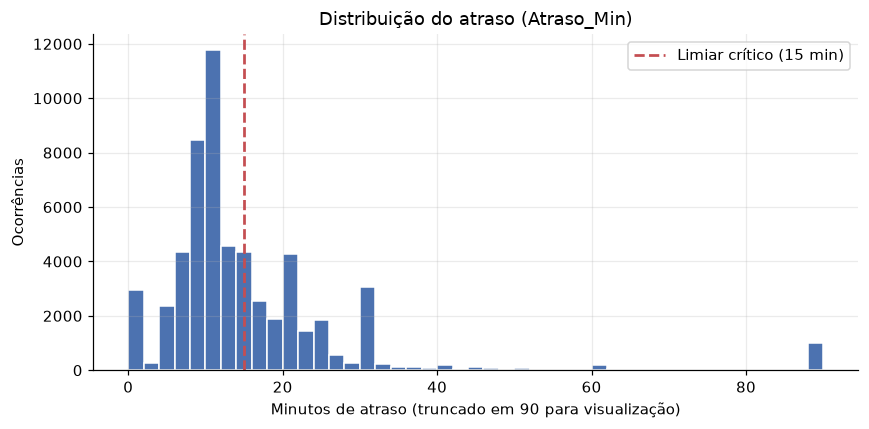

In [8]:
# Gráfico para mostrar a distribuição do atraso
fig, ax = plt.subplots(figsize=(8, 4))
# histograma com o atraso truncado em 90 min para que a cauda longa não esmague o gráfico
ax.hist(df_limpo["Atraso_Min"].clip(upper=90), bins=45, color="#4C72B0", edgecolor="white")
# linha vertical marcando o limiar a partir do qual o atraso é crítico
ax.axvline(LIMIAR_CRITICO, color="#C44E52", linestyle="--", linewidth=1.8, label=f"Limiar crítico ({LIMIAR_CRITICO} min)")
# título e rótulos dos eixos
ax.set_title("Distribuição do atraso (Atraso_Min)")
ax.set_xlabel("Minutos de atraso (truncado em 90 para visualização)")
ax.set_ylabel("Ocorrências")
ax.legend()
plt.tight_layout()
plt.show()

#### **5.3.2 Perfil por hora do dia**

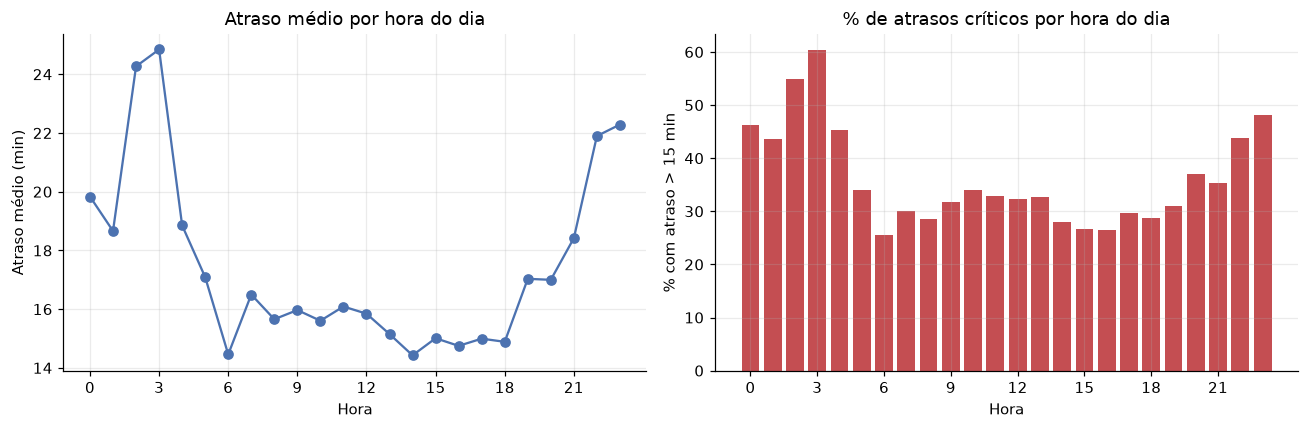

In [9]:
# Gráfico para mostrar o perfil por hora (atraso médio e % de atrasos críticos)
# atraso médio, percentual de críticos e volume de ocorrências agrupados por hora
por_hora = df_limpo.groupby("Hora").agg(atraso_medio=("Atraso_Min", "mean"), pct_critico=("Atraso_Critico", "mean"),
                                    ocorrencias=("Atraso_Min", "size"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# painel da esquerda com o atraso médio em cada hora
axes[0].plot(por_hora.index, por_hora["atraso_medio"], marker="o", color="#4C72B0")
axes[0].set_title("Atraso médio por hora do dia")
axes[0].set_xlabel("Hora"); axes[0].set_ylabel("Atraso médio (min)")
# painel da direita com o percentual de atrasos críticos em cada hora
axes[1].bar(por_hora.index, por_hora["pct_critico"] * 100, color="#C44E52")
axes[1].set_title("% de atrasos críticos por hora do dia")
axes[1].set_xlabel("Hora"); axes[1].set_ylabel("% com atraso > 15 min")
# marcações do eixo x de três em três horas para não poluir o gráfico
for ax in axes:
    ax.set_xticks(range(0, 24, 3))
plt.tight_layout()
plt.show()

#### **5.3.3 Incidentes mais frequentes**

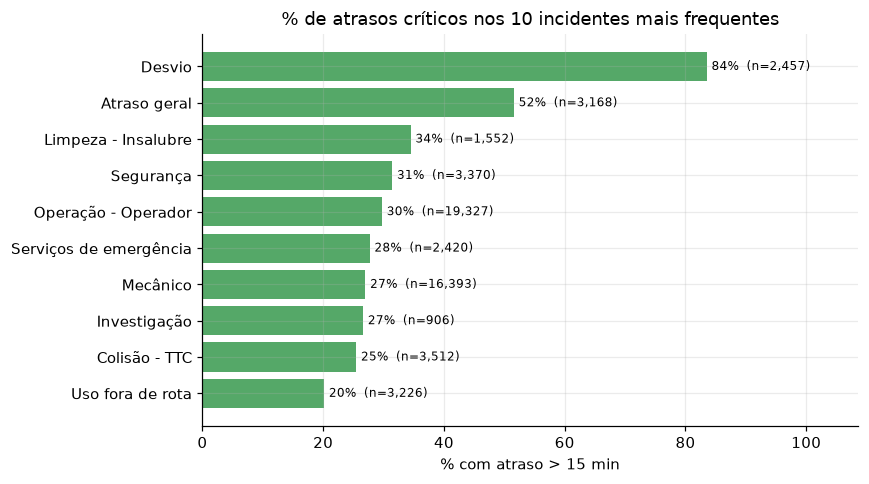

In [10]:
# Gráfico para mostrar os incidentes mais frequentes e sua taxa de atraso crítico
# seleção dos 10 incidentes com mais ocorrências e cálculo da taxa de atraso crítico de cada um
top_incidentes = (df_limpo.groupby("Incidente").agg(n=("Atraso_Min", "size"), pct_critico=("Atraso_Critico", "mean"))
          .nlargest(10, "n").sort_values("pct_critico"))
# barras horizontais ordenadas pela taxa de atraso crítico
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_incidentes.index, top_incidentes["pct_critico"] * 100, color="#55A868")
# anotação com o percentual e o tamanho da amostra em cada barra
for pos, (pct, n) in enumerate(zip(top_incidentes["pct_critico"] * 100, top_incidentes["n"])):
    ax.text(pct + 0.8, pos, f"{pct:.0f}%  (n={n:,})", va="center", fontsize=8)
# título e eixo x com folga à direita para caber as anotações
ax.set_title("% de atrasos críticos nos 10 incidentes mais frequentes")
ax.set_xlabel("% com atraso > 15 min"); ax.set_xlim(0, top_incidentes["pct_critico"].max() * 100 * 1.3)
plt.tight_layout()
plt.show()

#### **5.3.4 Leitura dos gráficos**

- **Distribuição do atraso.** A cauda é longa à direita: a mediana é de 11 min, mas a média passa de 20 min porque poucos eventos muito longos puxam o valor para cima. Cerca de um terço das ocorrências (32%) passa dos 15 min, o que nos dá um problema de classificação razoavelmente equilibrado.
- **Hora do dia.** A taxa de atrasos críticos é mais alta na madrugada (de 0h às 4h, entre 44% e 60%) e no fim da noite (22h e 23h, de 44% a 48%), e mais baixa entre 6h e 18h, na faixa de 26% a 34%. Vale lembrar que a madrugada tem poucas ocorrências (de 595 a 1.062 por hora, contra mais de 4.000 à tarde), então esses percentuais oscilam mais. Mesmo assim, a hora claramente carrega informação.
- **Incidente.** É o fator que mais separa os casos. Um *Desvio* gera atraso crítico em 84% das vezes e um *Atraso geral* em 52%, enquanto os incidentes de maior volume, *Operação - Operador* e *Mecânico*, ficam entre 27% e 30%. Para o SentaAI, desvio de rota é o sinal de maior risco.

### **5.4 Split treino/teste antes de qualquer transformação**

Dividimos os dados **antes** de qualquer transformação, porque é a ordem das etapas que evita o vazamento (*data leakage*):

1. Fazemos o `train_test_split` 80/20, estratificado em `Atraso_Critico` para manter a proporção das classes nos dois conjuntos.
2. Ajustamos o `StandardScaler` e o `OneHotEncoder` (`fit_transform`) somente no treino e só aplicamos (`transform`) no teste.

Deixamos o `Intervalo_Min` fora das variáveis preditoras. Ele só é medido junto com o atraso, ou seja, não existe no momento em que o SentaAI precisa prever. Usá-lo seria vazamento de alvo, e a Seção 6.3 mostra o tamanho do estrago nas métricas.

In [11]:
COLS_NUM = ["Hora_sen", "Hora_cos"]                           # padronizadas (StandardScaler)
COLS_CAT = ["Dia_Semana", "Incidente", "Direcao", "Rota"]          # codificadas (OneHotEncoder)
COLS_PREDITORAS = COLS_NUM + COLS_CAT

X = df_limpo[COLS_PREDITORAS + ["Intervalo_Min"]]      # Intervalo_Min fica disponível só para o teste de sanidade da Seção 6.3
y_reg = df_limpo["Atraso_Min"]
y_clf = df_limpo["Atraso_Critico"]

# SPLIT PRIMEIRO, com um único split para as duas tarefas, para que as mesmas linhas fiquem no teste
X_treino, X_teste, y_reg_treino, y_reg_teste, y_clf_treino, y_clf_teste = train_test_split(
    X, y_reg, y_clf, test_size=0.20, random_state=RANDOM_STATE, stratify=y_clf)


def construir_preprocessador(cols_num: list, cols_cat: list) -> ColumnTransformer:
    """Padroniza numéricas e aplica one-hot nas categóricas. Categorias raras (<50 ocorrências) são agrupadas."""
    return ColumnTransformer([
        ("num", StandardScaler(), cols_num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cols_cat),
    ])


# FIT SÓ NO TREINO, TRANSFORM NO TESTE
preprocessador = construir_preprocessador(COLS_NUM, COLS_CAT)
X_treino_p = preprocessador.fit_transform(X_treino[COLS_PREDITORAS])
X_teste_p = preprocessador.transform(X_teste[COLS_PREDITORAS])

print(f"Treino: {X_treino.shape[0]:,} linhas | Teste: {X_teste.shape[0]:,} linhas")
print(f"Features após o pré-processamento: {X_treino_p.shape[1]}")
print(f"% crítico: treino {y_clf_treino.mean() * 100:.1f}% | teste {y_clf_teste.mean() * 100:.1f}%")

Treino: 46,256 linhas | Teste: 11,564 linhas
Features após o pré-processamento: 181
% crítico: treino 32.4% | teste 32.4%


### **5.5 Variáveis que entram no modelo**

Por fim, registramos o que cada modelo realmente recebe: quais colunas são preditoras, qual o tipo original de cada uma, qual transformação foi aplicada e quantas colunas ela gerou na matriz final.

In [12]:
# nomes de todas as colunas geradas pelo pré-processador ajustado no treino
nomes_saida = preprocessador.get_feature_names_out()

# contagem de colunas geradas por variável, pois o OneHotEncoder cria uma coluna para cada categoria
colunas_geradas = [sum(n == f"num__{c}" for n in nomes_saida) for c in COLS_NUM] + \
                  [sum(n.startswith(f"cat__{c}_") for n in nomes_saida) for c in COLS_CAT]

resumo_variaveis = pd.DataFrame({
    "Tipo original": X_treino[COLS_PREDITORAS].dtypes.astype(str),
    "Transformação": ["StandardScaler"] * len(COLS_NUM) + ["OneHotEncoder"] * len(COLS_CAT),
    "Colunas geradas": colunas_geradas,
}).rename_axis("Variável preditora")
display(resumo_variaveis)

# formato final da matriz entregue aos modelos, com o total conferido contra a soma por variável
print(f"Matriz de treino: {X_treino_p.shape[0]:,} linhas x {X_treino_p.shape[1]} colunas")
print(f"Matriz de teste: {X_teste_p.shape[0]:,} linhas x {X_teste_p.shape[1]} colunas")
assert sum(colunas_geradas) == X_treino_p.shape[1]

,Tipo original,Transformação,Colunas geradas
Variável preditora,,,
Hora_sen,float64,StandardScaler,1
Hora_cos,float64,StandardScaler,1
Dia_Semana,object,OneHotEncoder,7
Incidente,object,OneHotEncoder,14
Direcao,object,OneHotEncoder,6
Rota,object,OneHotEncoder,152


Matriz de treino: 46,256 linhas x 181 colunas
Matriz de teste: 11,564 linhas x 181 colunas


**O que cada modelo recebe**

Seis variáveis preditoras viram 181 colunas numéricas. As duas variáveis cíclicas da hora geram uma coluna cada, já padronizadas. As quatro categóricas geram 179 colunas, porque o `OneHotEncoder` cria uma coluna por categoria: 7 para o dia, 14 para o incidente, 6 para a direção e 152 para a rota.

A rota é a que mais cresce. Das 250 categorias possíveis, só ficam colunas próprias as que têm pelo menos 50 ocorrências no treino, e as demais são agrupadas em uma única coluna de categorias raras. O mesmo vale para o incidente (14 de 15 categorias). Treino e teste têm o mesmo número de colunas (181), porque o teste só passa pelo `transform` do pré-processador ajustado no treino.

Ficam de fora das preditoras o `Atraso_Min`, que é o alvo da regressão linear, o `Atraso_Critico`, que é o alvo da regressão logística, e o `Intervalo_Min`, pelo vazamento de alvo explicado na Seção 5.4.

## **6. Regressão Linear (alvo: `Atraso_Min`)** *(Etapa 3)*

### **6.1 Treino e métricas**

Como referência, comparamos o modelo com um *baseline* ingênuo, que sempre prevê a média do treino. Se a regressão não superar essa linha de base, ela não tem valor prático.

In [13]:
# treino da regressão linear usando apenas os dados de treino já transformados
modelo_lin = LinearRegression().fit(X_treino_p, y_reg_treino)
pred_lin = modelo_lin.predict(X_teste_p)

# baseline ingênuo que prevê sempre a média do treino, para servir de comparação
baseline = np.full(len(y_reg_teste), y_reg_treino.mean())


# função que reúne MAE, RMSE e R² em um único dicionário
def metricas_regressao(y_real, y_prev) -> dict:
    return {"MAE (min)": mean_absolute_error(y_real, y_prev),
            "RMSE (min)": np.sqrt(mean_squared_error(y_real, y_prev)),
            "R²": r2_score(y_real, y_prev)}


# tabela comparando o baseline com a regressão linear no conjunto de teste
tabela_lin = pd.DataFrame({"Baseline (média do treino)": metricas_regressao(y_reg_teste, baseline),
                           "Regressão Linear": metricas_regressao(y_reg_teste, pred_lin)}).round(3)
tabela_lin

,Baseline (média do treino),Regressão Linear
MAE (min),9.879,6.733
RMSE (min),20.608,15.373
R²,-0.000,0.443


### **6.2 Avaliação gráfica**

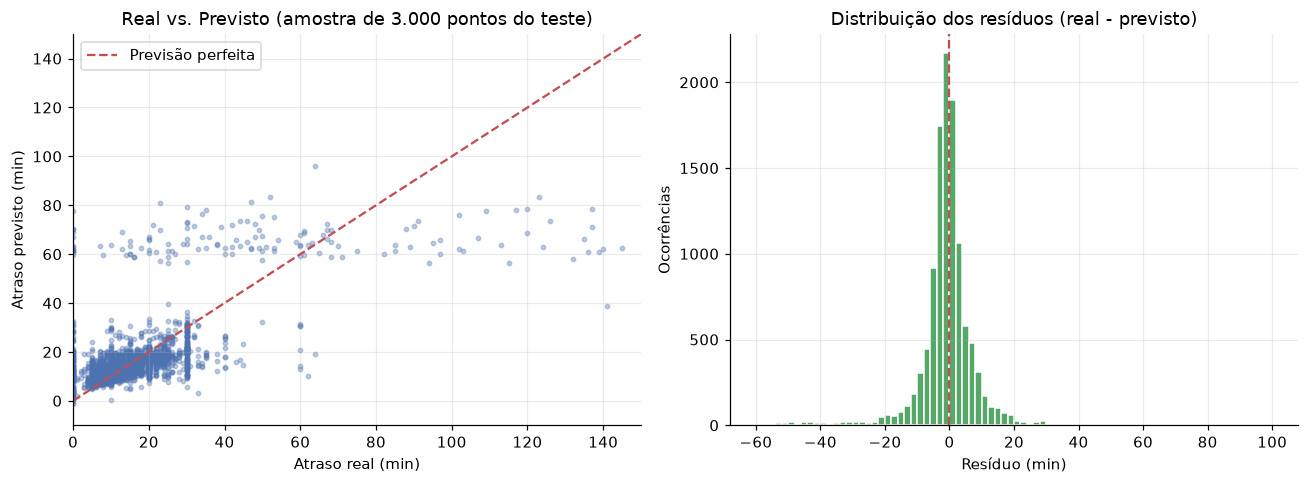

Previsões negativas (fisicamente impossíveis): 0.1% do teste


In [14]:
# o resíduo é a diferença entre o atraso real e o previsto
residuos = y_reg_teste.to_numpy() - pred_lin
# amostra aleatória de 3.000 pontos para que o gráfico de dispersão não fique ilegível
amostra = np.random.default_rng(RANDOM_STATE).choice(len(y_reg_teste), size=3000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_reg_teste.to_numpy()[amostra], pred_lin[amostra], s=8, alpha=0.35, color="#4C72B0")
# linha de previsão perfeita, em que o previsto seria igual ao real
axes[0].plot([0, 150], [0, 150], color="#C44E52", linestyle="--", label="Previsão perfeita")
axes[0].set_xlim(0, 150); axes[0].set_ylim(-10, 150)
axes[0].set_title("Real vs. Previsto (amostra de 3.000 pontos do teste)")
axes[0].set_xlabel("Atraso real (min)"); axes[0].set_ylabel("Atraso previsto (min)")
axes[0].legend()

# histograma dos resíduos, que deve ficar centrado em zero
axes[1].hist(residuos, bins=80, range=(-60, 100), color="#55A868", edgecolor="white")
axes[1].axvline(0, color="#C44E52", linestyle="--")
axes[1].set_title("Distribuição dos resíduos (real - previsto)")
axes[1].set_xlabel("Resíduo (min)"); axes[1].set_ylabel("Ocorrências")
plt.tight_layout()
plt.show()

# a regressão linear não limita a saída em zero, então conferimos quantas previsões saíram negativas
print(f"Previsões negativas (fisicamente impossíveis): {(pred_lin < 0).mean() * 100:.1f}% do teste")

#### **6.2.1 Interpretação dos resultados**

| Métrica | Baseline (média) | Regressão Linear | O que significa |
|:---|:-:|:-:|:---|
| MAE | 9,88 min | 6,73 min | A previsão erra, em média, 6,7 min, cerca de 32% menos que prever sempre a média |
| RMSE | 20,61 min | 15,37 min | Fica acima do MAE porque pune mais os erros grandes, que vêm dos atrasos longos |
| R² | 0,00 | 0,44 | O modelo explica cerca de 44% da variação do atraso |

O modelo supera a linha de base nas três métricas, então hora, dia, direção, rota e tipo de incidente têm poder preditivo. Os resíduos ficam centrados em zero e concentrados (gráfico da direita), sem viés para cima ou para baixo.

O ponto fraco aparece no gráfico *Real vs. Previsto*: há uma faixa de previsões entre 60 e 80 min, que corresponde aos desvios. O modelo acerta que o atraso será longo, mas não distingue um desvio de 30 min de um de 140 min, e subestima os extremos. Só 0,1% das previsões saiu negativo, algo que o modelo linear permite por não limitar a saída em zero. Para uso operacional, basta truncar em 0.

#### **6.2.2 Por que um R² de 0,44 é esperado aqui**

Atraso de ônibus em área urbana depende de muita coisa que a base da TTC não registra: clima (neve, chuva), volume de trânsito no momento, obras, eventos na cidade, condição da via. Nenhuma dessas variáveis está na nossa base, e é natural que elas respondam por boa parte da variação que o modelo não explica. Um R² por volta de 0,44 com apenas hora, dia, rota, direção e incidente é um resultado razoável para esse tipo de dado, e não sinal de um modelo mal construído.

Isso também define o papel de cada modelo no SentaAI. A regressão linear serve para estimar **faixas** de atraso (curto, médio, longo), não o minuto exato. Já a **Regressão Logística** é mais estratégica para o painel de alertas: o painel precisa decidir se avisa ou não o passageiro, e acertar essa decisão binária é mais fácil e mais útil do que acertar o minuto exato da chegada. A Seção 7 mostra isso com um ROC-AUC de 0,88.

### **6.3 Teste de sanidade: por que `Intervalo_Min` fica fora do modelo**

Para medir o tamanho do problema, retreinamos o mesmo modelo **incluindo** o `Intervalo_Min` e comparamos o R².

In [15]:
# correlação entre o intervalo e o atraso para medir o quanto um depende do outro
corr_intervalo = df_limpo["Intervalo_Min"].corr(df_limpo["Atraso_Min"])
pct_intervalo_maior = (df_limpo["Intervalo_Min"] >= df_limpo["Atraso_Min"]).mean() * 100
print(f"Correlação Intervalo_Min x Atraso_Min: {corr_intervalo:.2f} | Intervalo_Min >= Atraso_Min em {pct_intervalo_maior:.1f}% das linhas\n")

# mesmo pré-processamento de antes, agora incluindo o Intervalo_Min como variável numérica
prep_intervalo = construir_preprocessador(COLS_NUM + ["Intervalo_Min"], COLS_CAT)
Xtr_intervalo = prep_intervalo.fit_transform(X_treino[COLS_PREDITORAS + ["Intervalo_Min"]])
Xte_intervalo = prep_intervalo.transform(X_teste[COLS_PREDITORAS + ["Intervalo_Min"]])
# retreino do modelo com o Intervalo_Min e cálculo do R² no teste
r2_intervalo = r2_score(y_reg_teste, LinearRegression().fit(Xtr_intervalo, y_reg_treino).predict(Xte_intervalo))

# comparação do R² com e sem o Intervalo_Min
pd.DataFrame({"R² no teste": {"Sem Intervalo_Min (modelo adotado)": r2_score(y_reg_teste, pred_lin),
                              "Com Intervalo_Min (vazamento)": r2_intervalo}}).round(3)

Correlação Intervalo_Min x Atraso_Min: 0.92 | Intervalo_Min >= Atraso_Min em 99.1% das linhas



,R² no teste
Sem Intervalo_Min (modelo adotado),0.443
Com Intervalo_Min (vazamento),0.872


#### **6.3.1 Conclusão do teste**

O `Intervalo_Min` é praticamente uma consequência do atraso: a correlação entre os dois é de 0,92, e o intervalo é maior ou igual ao atraso em 99,1% das linhas. Incluí-lo eleva o R² de 0,44 para 0,87, mas o ganho é ilusório, porque o valor só é conhecido depois que o atraso já aconteceu. No momento da previsão, o SentaAI não teria essa informação. Por isso, o modelo adotado não usa o `Intervalo_Min`, e as métricas da Seção 6.1 são as que refletem o uso real.

## **7. Regressão Logística (alvo: `Atraso_Critico`)** *(Etapa 4)*

Optamos por `class_weight="balanced"`. A classe crítica é minoria (cerca de um terço dos casos), e sem o peso o modelo tenderia a prever sempre "normal". Para o SentaAI, deixar de avisar sobre um ônibus lotado custa mais do que um alerta desnecessário, então o *recall* da classe crítica é a nossa métrica prioritária.

### **7.1 Treino, matriz de confusão e métricas**

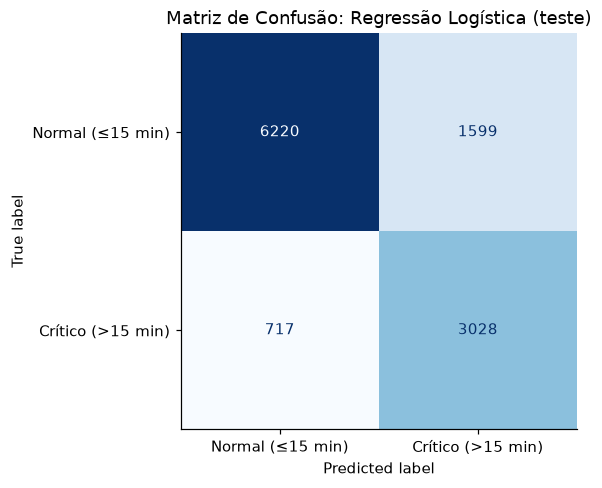

In [16]:
# regressão logística com pesos balanceados entre as classes, já que a classe crítica é minoria
modelo_log = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
modelo_log.fit(X_treino_p, y_clf_treino)

# classe prevista com o corte padrão de 0,50 e probabilidade de o atraso ser crítico
pred_log = modelo_log.predict(X_teste_p)
proba_log = modelo_log.predict_proba(X_teste_p)[:, 1]

# matriz de confusão visual do conjunto de teste
fig, ax = plt.subplots(figsize=(5.2, 4.6))
ConfusionMatrixDisplay.from_predictions(
    y_clf_teste, pred_log, display_labels=["Normal (≤15 min)", "Crítico (>15 min)"],
    cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Matriz de Confusão: Regressão Logística (teste)")
ax.grid(False)
plt.tight_layout()
plt.show()

In [17]:
# métricas da classe crítica, que é a que mais importa para o SentaAI
tabela_log = pd.DataFrame({
    "Precisão": [precision_score(y_clf_teste, pred_log)],
    "Recall": [recall_score(y_clf_teste, pred_log)],
    "F1-Score": [f1_score(y_clf_teste, pred_log)],
    "ROC-AUC": [roc_auc_score(y_clf_teste, proba_log)],
}, index=["Classe crítica (1)"]).round(3)
# exibe a tabela de métricas formatada
display(tabela_log)

# relatório completo com as métricas das duas classes
print(classification_report(y_clf_teste, pred_log, target_names=["Normal (0)", "Crítico (1)"], digits=3))

,Precisão,Recall,F1-Score,ROC-AUC
Classe crítica (1),0.654,0.809,0.723,0.879


              precision    recall  f1-score   support

  Normal (0)      0.897     0.795     0.843      7819
 Crítico (1)      0.654     0.809     0.723      3745

    accuracy                          0.800     11564
   macro avg      0.776     0.802     0.783     11564
weighted avg      0.818     0.800     0.804     11564



#### **7.1.1 Interpretação dos resultados** *(limiar padrão de 0,50)*

| Métrica | Valor | O que significa para o SentaAI |
|:---|:-:|:---|
| Recall (classe crítica) | 0,81 | De cada 100 atrasos críticos, o modelo identifica 81. Os outros 717 do teste passam sem alerta (falsos negativos) |
| Precisão (classe crítica) | 0,65 | De cada 100 alertas emitidos, 65 se confirmam. Foram 1.599 alertas falsos |
| F1-Score | 0,72 | Equilíbrio entre precisão e recall |
| ROC-AUC | 0,88 | Dado um par (crítico, normal), o modelo dá probabilidade maior ao crítico em 88% das vezes |
| Acurácia | 0,80 | Informativa, mas menos importante que o recall quando as classes são desiguais |

O `class_weight="balanced"` fez o modelo priorizar a classe crítica: ganhamos recall (0,81) e pagamos em precisão (0,65). É a troca que queríamos, já que um alerta desnecessário custa pouco ao passageiro, e um atraso crítico sem aviso significa esperar em um ponto lotado. A matriz de confusão confirma isso, com mais falsos positivos (1.599) do que falsos negativos (717).

### **7.2 Ajuste de threshold: regra de negócio do SentaAI**

O corte padrão de 0,50 trata os dois erros como igualmente graves, e para o painel eles não são. Um falso positivo é um aviso de lotação que não se confirma. Um falso negativo é um ônibus cheio que o painel deixou passar como normal, e o passageiro só descobre isso na porta. Por isso, comparamos o corte padrão com um mais sensível, de 0,35.

Fixamos o 0,35 como regra de negócio, e não pelo melhor desempenho no teste. Escolher o limiar olhando o teste seria um vazamento. Em produção, o ideal é calibrá-lo com um conjunto de validação.

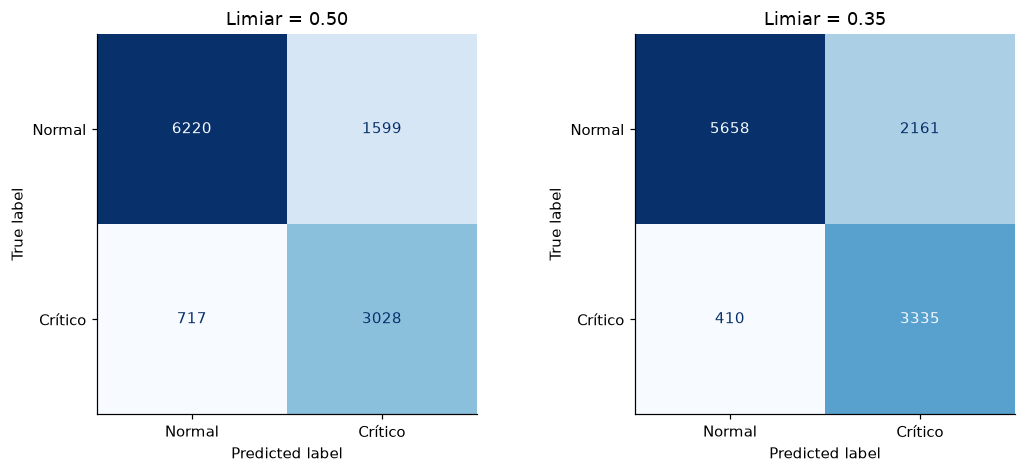

,Precisão,Recall,F1-Score,Falsos negativos,Falsos positivos
Limiar 0.50 (padrão),0.654,0.809,0.723,717,1599
Limiar 0.35 (sensível),0.607,0.891,0.722,410,2161


Probabilidade média prevista: 0.42 | taxa real de atrasos críticos no teste: 0.32


In [18]:
LIMIAR_PADRAO = 0.50
LIMIAR_SENSIVEL = 0.35     # regra de negócio que prioriza o recall, ou seja, menos falsos negativos


# função que aplica um limiar às probabilidades e calcula as métricas correspondentes
def avaliar_limiar(y_real, probabilidades, limiar):
    """Classifica como crítico quando a probabilidade >= limiar e devolve predições e métricas."""
    pred = (probabilidades >= limiar).astype(int)
    _, fp, fn, _ = confusion_matrix(y_real, pred).ravel()
    return pred, {"Precisão": precision_score(y_real, pred), "Recall": recall_score(y_real, pred),
                  "F1-Score": f1_score(y_real, pred), "Falsos negativos": fn, "Falsos positivos": fp}


# avaliação do mesmo modelo com os dois limiares, o padrão e o sensível
pred_padrao, met_padrao = avaliar_limiar(y_clf_teste, proba_log, LIMIAR_PADRAO)
pred_sensivel, met_sensivel = avaliar_limiar(y_clf_teste, proba_log, LIMIAR_SENSIVEL)

# matrizes de confusão lado a lado para comparar os dois limiares
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, pred, limiar in zip(axes, [pred_padrao, pred_sensivel], [LIMIAR_PADRAO, LIMIAR_SENSIVEL]):
    ConfusionMatrixDisplay.from_predictions(y_clf_teste, pred, display_labels=["Normal", "Crítico"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Limiar = {limiar:.2f}")
    ax.grid(False)
plt.tight_layout()
plt.show()

# tabela comparativa com precisão, recall, F1 e a contagem de erros
comparacao = pd.DataFrame({f"Limiar {LIMIAR_PADRAO:.2f} (padrão)": met_padrao,
                           f"Limiar {LIMIAR_SENSIVEL:.2f} (sensível)": met_sensivel}).T
comparacao[["Falsos negativos", "Falsos positivos"]] = comparacao[["Falsos negativos", "Falsos positivos"]].astype(int)
display(comparacao.round(3))

# checagem de calibração, comparando a probabilidade média prevista com a taxa real
print(f"Probabilidade média prevista: {proba_log.mean():.2f} | taxa real de atrasos críticos no teste: {y_clf_teste.mean():.2f}")

#### **7.2.1 O que mudou com o limiar de 0,35**

| Limiar | Precisão | Recall | F1 | Falsos negativos | Falsos positivos |
|:---|:-:|:-:|:-:|:-:|:-:|
| 0,50 (padrão) | 0,654 | 0,809 | 0,723 | 717 | 1.599 |
| 0,35 (sensível) | 0,607 | 0,891 | 0,722 | 410 | 2.161 |

Ao baixar o corte, o recall sobe de 0,81 para 0,89 e os falsos negativos caem de 717 para 410, uma redução de 43%. O preço são 562 falsos positivos a mais (35% a mais de avisos que não se confirmam) e uma queda de 5 pontos na precisão. O F1 praticamente não muda (0,723 contra 0,722), então o modelo não ficou pior no geral, só trocou de tipo de erro.

Para o SentaAI, essa troca vale a pena. Um falso positivo faz o passageiro ver um aviso de lotação que não se confirma, e o custo é pequeno. Um falso negativo deixa o painel mostrando "normal" para um ônibus que vai chegar lotado, e o passageiro percebe isso só quando o veículo para na porta. Como o segundo erro é o que quebra a promessa do produto, adotamos 0,35 como limiar do painel.

#### **7.2.2 Um cuidado sobre a probabilidade**

A probabilidade média prevista (0,42) ficou acima da taxa real de atrasos críticos (0,32). Isso é efeito do `class_weight="balanced"`, que desloca as probabilidades para cima. Por isso, a saída do modelo funciona melhor como um **índice de risco** para ordenar e comparar casos do que como uma probabilidade calibrada. Calibrar as probabilidades, por exemplo com `CalibratedClassifierCV`, é um passo natural antes de levar o painel à operação.

### **7.3 Interpretabilidade dos modelos**

Para entender o que cada modelo aprendeu, cruzamos os coeficientes (`coef_`) com os nomes das colunas geradas pelo `preprocessador`. Mostramos os 10 fatores categóricos (incidentes, rotas, dias e direções) que mais empurram o atraso e o risco de superlotação para cima. A hora do dia entra no modelo como seno e cosseno, então não existe um coeficiente único para "18h"; o efeito dela aparece nas curvas do gráfico de EDA.

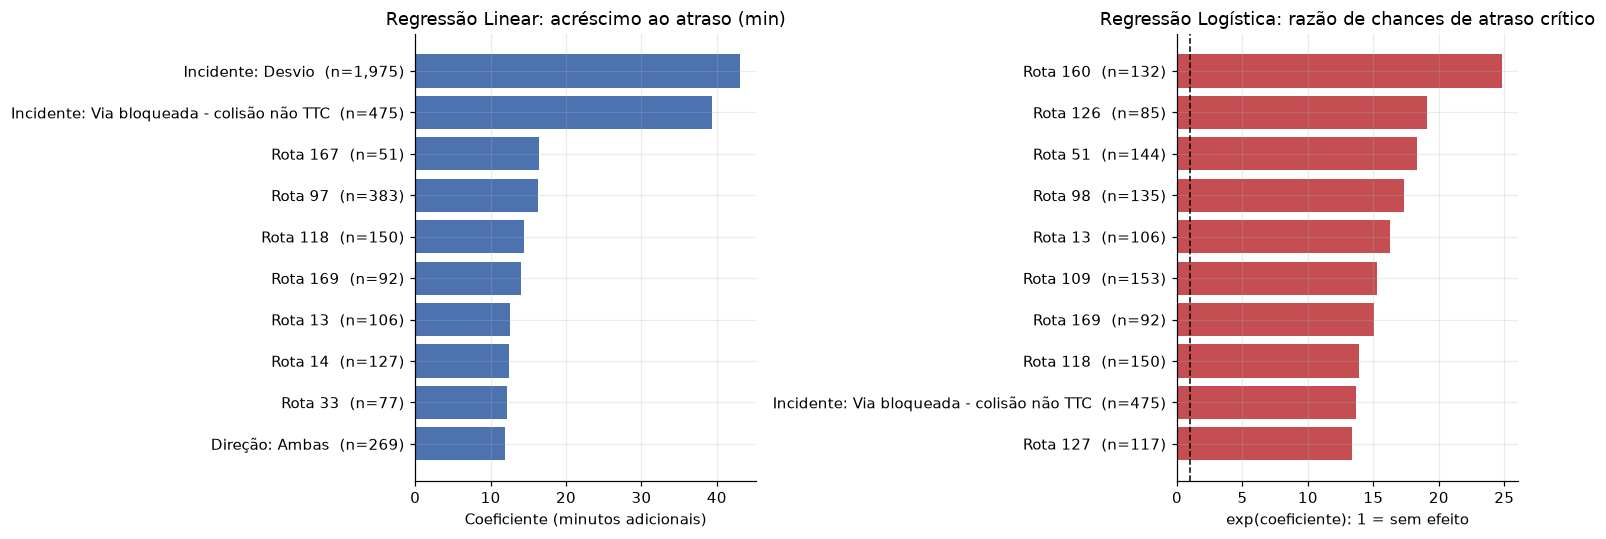

Coeficientes da hora na regressão linear: Hora_sen = 0.19 | Hora_cos = 0.90


In [19]:
# nomes das colunas geradas pelo pré-processador, na mesma ordem dos coeficientes
nomes_colunas = preprocessador.get_feature_names_out()


def rotulo_legivel(nome: str) -> str:
    """Transforma 'cat__Incidente_Desvio' em 'Incidente: Desvio'."""
    nome = nome.replace("cat__", "")
    for prefixo, rotulo in [("Incidente_", "Incidente: "), ("Rota_", "Rota "),
                            ("Dia_Semana_", "Dia: "), ("Direcao_", "Direção: ")]:
        if nome.startswith(prefixo):
            nome = rotulo + nome[len(prefixo):]
    return nome.replace("infrequent_sklearn", "(agrupadas, raras)")


# separamos as colunas categóricas, pois a hora cíclica não tem coeficiente interpretável sozinha
eh_categorica = np.array([n.startswith("cat__") for n in nomes_colunas])
rotulos = np.array([rotulo_legivel(n) for n in nomes_colunas])

coef_lin = pd.Series(modelo_lin.coef_, index=rotulos)[eh_categorica]
razao_chances = pd.Series(np.exp(modelo_log.coef_[0]), index=rotulos)[eh_categorica]   # exp(coef) = razão de chances

# Tamanho da amostra de cada categoria no treino, já que coeficientes de categorias raras são menos confiáveis
contagem = {rotulo_legivel(f"cat__{col}_{valor}"): n
            for col in COLS_CAT for valor, n in X_treino[col].value_counts().items()}


def com_n(serie: pd.Series) -> pd.Series:
    serie = serie.copy()
    serie.index = [f"{r}  (n={contagem[r]:,})" if r in contagem else r for r in serie.index]
    return serie


# 10 maiores coeficientes de cada modelo, invertidos para que o maior fique no topo do gráfico
top_lin = com_n(coef_lin.nlargest(10)).iloc[::-1]
top_log = com_n(razao_chances.nlargest(10)).iloc[::-1]

# gráficos de barras horizontais lado a lado, um para cada modelo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top_lin.index, top_lin.values, color="#4C72B0")
axes[0].set_title("Regressão Linear: acréscimo ao atraso (min)")
axes[0].set_xlabel("Coeficiente (minutos adicionais)")
axes[1].barh(top_log.index, top_log.values, color="#C44E52")
axes[1].axvline(1, color="black", linewidth=1, linestyle="--")
axes[1].set_title("Regressão Logística: razão de chances de atraso crítico")
axes[1].set_xlabel("exp(coeficiente): 1 = sem efeito")
plt.tight_layout()
plt.show()

print(f"Coeficientes da hora na regressão linear: Hora_sen = {modelo_lin.coef_[0]:.2f} | Hora_cos = {modelo_lin.coef_[1]:.2f}")

#### **7.3.1 O que os coeficientes indicam**

- **Regressão Linear.** Os maiores acréscimos de atraso vêm dos incidentes: um *Desvio* soma cerca de 43 min e uma *Via bloqueada por colisão não TTC* cerca de 39 min, bem acima de qualquer outro fator. Depois deles aparecem algumas rotas (167, 97, 118, 169, 13, 14 e 33), com acréscimos de 12 a 16 min, e as ocorrências em que a direção é *Ambas*.
- **Regressão Logística.** A razão de chances mostra quantas vezes a chance de atraso crítico aumenta com cada fator. O topo é ocupado por rotas (160, 126, 51, 98, 13, 109, 169, 118 e 127), com razões entre 13 e 25, e pela *Via bloqueada*. O *Desvio* tem razão de chances de cerca de 12 e fica logo fora do gráfico, na 13ª posição.
- **Rotas no topo: cuidado.** Quase todas as rotas desse ranking têm poucos registros no treino (entre 85 e 153 ocorrências cada), contra 1.975 do *Desvio* e 475 da *Via bloqueada*. Com amostras assim pequenas, a razão de chances varia muito de um registro para outro, e não temos base para afirmar que essas linhas são realmente as mais problemáticas. Também não conseguimos dizer, só com essa base, por que certas linhas concentram atrasos críticos. Pode ser um serviço com intervalos longos entre os ônibus, o que favorece o efeito comboio, ou pode ser outro motivo. Tratamos isso como uma hipótese a investigar com os dados de catraca e de frequência das linhas.
- **Incidentes: o sinal mais confiável.** Já os incidentes, com amostras grandes, aparecem de forma consistente nos dois modelos. É por eles que o SentaAI deve começar.

#### **7.3.2 Ressalvas de leitura**

Como o `OneHotEncoder` cria uma coluna para cada categoria, os coeficientes servem para comparar categorias da mesma variável entre si, e não como efeitos isolados. E categorias com poucos registros (o `n` aparece em cada barra) têm coeficientes menos estáveis.

### **7.4 Salvando os modelos (`.pkl`)**

Cada arquivo guarda um `Pipeline` completo, com o pré-processador ajustado no treino e o modelo treinado. Assim, a central do SentaAI carrega o arquivo e prevê direto a partir das colunas brutas, sem refazer o `StandardScaler` e o `OneHotEncoder` à mão.

In [20]:
import pickle
from pathlib import Path
from sklearn.pipeline import Pipeline

# pasta onde os arquivos dos modelos serão gravados
PASTA_MODELOS = Path("modelos")
PASTA_MODELOS.mkdir(exist_ok=True)

# Pipelines montados com componentes JÁ ajustados no treino (nenhum novo fit acontece aqui)
pipeline_linear = Pipeline([("preprocessador", preprocessador), ("modelo", modelo_lin)])
pipeline_logistico = Pipeline([("preprocessador", preprocessador), ("modelo", modelo_log)])

# um arquivo para cada modelo, com o pipeline completo
arquivos = {"modelo_regressao_linear.pkl": pipeline_linear,
            "modelo_regressao_logistica.pkl": pipeline_logistico}

# gravação de cada pipeline em formato pickle
for nome, pipeline in arquivos.items():
    with open(PASTA_MODELOS / nome, "wb") as f:
        pickle.dump(pipeline, f)

# Verificação de que o modelo recarregado reproduz exatamente as previsões do teste
with open(PASTA_MODELOS / "modelo_regressao_linear.pkl", "rb") as f:
    linear_carregado = pickle.load(f)
with open(PASTA_MODELOS / "modelo_regressao_logistica.pkl", "rb") as f:
    logistico_carregado = pickle.load(f)

assert np.allclose(linear_carregado.predict(X_teste[COLS_PREDITORAS]), pred_lin)
assert np.array_equal(logistico_carregado.predict(X_teste[COLS_PREDITORAS]), pred_log)

# tamanho final dos arquivos gerados
for nome in arquivos:
    print(f"{nome}: {(PASTA_MODELOS / nome).stat().st_size / 1024:.1f} KB")
print("Modelos salvos e verificados.")

modelo_regressao_linear.pkl: 8.0 KB
modelo_regressao_logistica.pkl: 8.3 KB
Modelos salvos e verificados.


#### **7.4.1 Exemplo de uso**

O arquivo recebe um `DataFrame` com as colunas `Hora_sen`, `Hora_cos`, `Dia_Semana`, `Incidente`, `Direcao` e `Rota`.

```python
with open("modelos/modelo_regressao_logistica.pkl", "rb") as f:
    modelo = pickle.load(f)
probabilidade_critico = modelo.predict_proba(novos_registros)[:, 1]
```

Carregue apenas arquivos `.pkl` de origem confiável e com a mesma versão do `scikit-learn` usada no treino.

## **8. Recomendações, Limitações e Impactos** *(Etapa 5)*

### **8.1 Conclusão executiva**

Com informações simples e disponíveis no momento da ocorrência (hora, dia, direção, rota e tipo de incidente), conseguimos estimar **quanto** um ônibus vai atrasar (erro médio de 6,7 min) e **se** o atraso será crítico (recall de 0,81 no corte padrão, 0,89 no corte sensível, e ROC-AUC de 0,88). O tipo de incidente é o sinal mais forte, e desvios de rota geram atraso crítico em 84% dos casos. Dos dois modelos, a Regressão Logística é a mais útil para o painel, porque a decisão de avisar ou não o passageiro é binária.

### **8.2 (a) Como a central do SentaAI usa essas previsões**

Quando um incidente é registrado, a central calcula o risco de atraso crítico e o atraso estimado, e responde de forma proporcional. Os níveis abaixo são uma proposta de operação nossa, ainda sem validação em campo:

| Risco (saída da Regressão Logística) | Status | Ação para a frota | Ação para o passageiro |
|:---|:---|:---|:---|
| Abaixo de 20% | Normal | Nenhuma | A tela externa mostra a lotação normalmente |
| De 20% a 35% | Atenção | O gestor recebe um aviso e deixa reforço em standby | Aviso discreto de possível atraso |
| A partir de 35% | Alerta | O gestor avalia despachar um ônibus de reforço ou antecipar o veículo seguinte | Alerta com o atraso estimado e sugestão de linha alternativa |

Os dados de catraca e de sensores de porta da solução original entram como segunda camada. O atraso indica **onde** o acúmulo de passageiros tende a acontecer, e os sensores confirmam **o quanto** o veículo realmente lotou.

### **8.3 (b) Limitações do modelo**

1. **A base só registra ocorrências de atraso.** Não há viagens sem incidente, então o risco calculado vale depois que um incidente foi registrado. O modelo não prevê se um incidente vai acontecer.
2. **O tipo de incidente só é conhecido depois do evento.** O modelo funciona como ferramenta de resposta rápida, que estima a duração depois que o incidente é reportado, e não como previsão antecipada.
3. **Faltam variáveis climáticas e de trânsito.** Neve, chuva, temperatura e volume de tráfego influenciam os atrasos e não estão na base. É a principal razão de o R² ficar em 0,44.
4. **Faltam dados reais de catraca e ocupação.** A ligação entre atraso e superlotação é a premissa do projeto, mas não foi medida aqui, porque a base de Toronto não registra quantos passageiros estavam a bordo. Essa validação depende dos dados da solução original.
5. **As probabilidades não são calibradas.** O `class_weight="balanced"` desloca a saída para cima (média de 0,42 contra 0,32 reais), então ela deve ser lida como índice de risco.
6. **A validação foi aleatória.** O split 80/20 mistura datas. Para um sistema que prevê o futuro, uma validação temporal (treinar nos primeiros meses e testar nos seguintes) seria mais rigorosa.
7. **Os dados são de uma única cidade e de um único ano.** Características locais de Toronto em 2022 limitam a generalização para outras cidades e períodos.

### **8.4 Próximos passos**

Incorporar dados meteorológicos, testar modelos não lineares (como *gradient boosting*), adotar validação temporal, calibrar as probabilidades e, principalmente, cruzar as previsões com dados reais de lotação.

### **8.5 (c) Impacto para o cidadão**

- **Menos incerteza na espera.** O passageiro sabe, antes de embarcar, se o próximo ônibus tende a vir atrasado ou cheio, e decide se espera ou procura outra linha.
- **Melhor uso do tempo.** Alertas antecipados reduzem a espera sem informação nos pontos, principalmente à noite e na madrugada, quando os atrasos críticos são mais frequentes.
- **Acessibilidade.** Idosos, pessoas com mobilidade reduzida e quem viaja com crianças ou cargas ganham ao saber se haverá assento antes de subir.
- **Serviço mais eficiente.** Reforços enviados para onde o atraso gera acúmulo, em vez de um aumento uniforme da frota, melhoram o atendimento sem custo proporcional.

## **9. Anexo: Simulação de inferência no painel do SentaAI**

Para fechar, simulamos três cenários de operação na mesma linha e no mesmo sentido (rota 32, sentido leste), de modo que só mudem o dia, a hora e o incidente. Cada um passa pelo `preprocessador` e pelos dois modelos já treinados, e a saída segue o formato que o painel exibiria. O status usa a regra de negócio da Seção 7.2: probabilidade a partir de 0,35 gera **ALERTA**, entre 0,20 e 0,35 gera **ATENÇÃO**, e abaixo de 0,20 o painel segue **NORMAL**.

In [21]:
LIMIAR_ATENCAO = 0.20
LIMIAR_ALERTA = LIMIAR_SENSIVEL


# função que monta uma linha de entrada com as mesmas colunas usadas no treino
def montar_entrada(hora, dia, incidente, direcao, rota) -> dict:
    """Monta uma linha com as mesmas colunas usadas no treino (inclui a codificação cíclica da hora)."""
    return {"Hora_sen": np.sin(2 * np.pi * hora / 24), "Hora_cos": np.cos(2 * np.pi * hora / 24),
            "Dia_Semana": dia, "Incidente": incidente, "Direcao": direcao, "Rota": rota}


# função que converte a probabilidade no status exibido no painel
def status_alerta(probabilidade: float) -> str:
    if probabilidade >= LIMIAR_ALERTA:
        return "ALERTA"
    return "ATENÇÃO" if probabilidade >= LIMIAR_ATENCAO else "NORMAL"


# três cenários de operação que vamos simular
cenarios = [
    {"titulo": "Horário de pico com incidente mecânico", "hora": 18, "dia": "Sexta", "incidente": "Mecânico", "direcao": "L", "rota": "32"},
    {"titulo": "Domingo de manhã, operação de rotina", "hora": 9, "dia": "Domingo", "incidente": "Operação - Operador", "direcao": "L", "rota": "32"},
    {"titulo": "Noite com desvio de rota", "hora": 23, "dia": "Quinta", "incidente": "Desvio", "direcao": "L", "rota": "32"},
]

# os cenários passam pelo mesmo pré-processador ajustado no treino
entrada = pd.DataFrame([montar_entrada(c["hora"], c["dia"], c["incidente"], c["direcao"], c["rota"]) for c in cenarios])
entrada_p = preprocessador.transform(entrada[COLS_PREDITORAS])

atrasos = np.clip(modelo_lin.predict(entrada_p), 0, None)          # atraso negativo não existe, então truncamos em 0
# probabilidade de atraso crítico vinda da regressão logística
probabilidades = modelo_log.predict_proba(entrada_p)[:, 1]

# impressão no formato do painel do SentaAI
for c, atraso, prob in zip(cenarios, atrasos, probabilidades):
    print("=" * 58)
    print(f" SentaAI | Rota {c['rota']} sentido {c['direcao']} | {c['dia']}, {c['hora']:02d}h")
    print(f" Cenário: {c['titulo']} ({c['incidente']})")
    print("-" * 58)
    print(f" Atraso estimado ............ {atraso:5.0f} min")
    print(f" Probabilidade superlotação . {prob * 100:5.0f} %")
    print(f" Status do alerta ........... {status_alerta(prob)}")
print("=" * 58)

 SentaAI | Rota 32 sentido L | Sexta, 18h
 Cenário: Horário de pico com incidente mecânico (Mecânico)
----------------------------------------------------------
 Atraso estimado ............    12 min
 Probabilidade superlotação .    19 %
 Status do alerta ........... NORMAL
 SentaAI | Rota 32 sentido L | Domingo, 09h
 Cenário: Domingo de manhã, operação de rotina (Operação - Operador)
----------------------------------------------------------
 Atraso estimado ............    14 min
 Probabilidade superlotação .    30 %
 Status do alerta ........... ATENÇÃO
 SentaAI | Rota 32 sentido L | Quinta, 23h
 Cenário: Noite com desvio de rota (Desvio)
----------------------------------------------------------
 Atraso estimado ............    65 min
 Probabilidade superlotação .    91 %
 Status do alerta ........... ALERTA


### **9.1 Como lemos a simulação**

| Cenário | Atraso estimado | Probabilidade | Status |
|:---|:-:|:-:|:-:|
| Sexta, 18h, incidente mecânico | 12 min | 19% | NORMAL |
| Domingo, 9h, operação de rotina | 14 min | 30% | ATENÇÃO |
| Quinta, 23h, desvio de rota | 65 min | 91% | ALERTA |

O resultado que mais chama a atenção é que o horário de pico com incidente mecânico fica **abaixo** do domingo de manhã em rotina. Isso vem dos dados, e não de um erro: nos registros de 2022, a taxa de atrasos críticos é de 39% aos domingos contra 31% na sexta, e nas horas de pico (17h às 19h) ela é de 30%, levemente abaixo da média geral de 32%. Em outras palavras, o pico gera mais ocorrências, mas não atrasos proporcionalmente mais longos, e o incidente mecânico (27% de críticos) não é um dos mais graves. O desvio de rota, esse sim, domina a previsão, com 65 min de atraso estimado e 91% de risco.

O cenário também deixa uma limitação clara. O modelo prevê a gravidade do **atraso**, não a lotação em si. Um ônibus pode estar cheio em plena hora de pico mesmo sem atraso, e é aí que os dados de catraca e de sensores de porta da solução original completam o quadro.